# Назначение самолёта по фотографии: сравнение двух локальных VLM

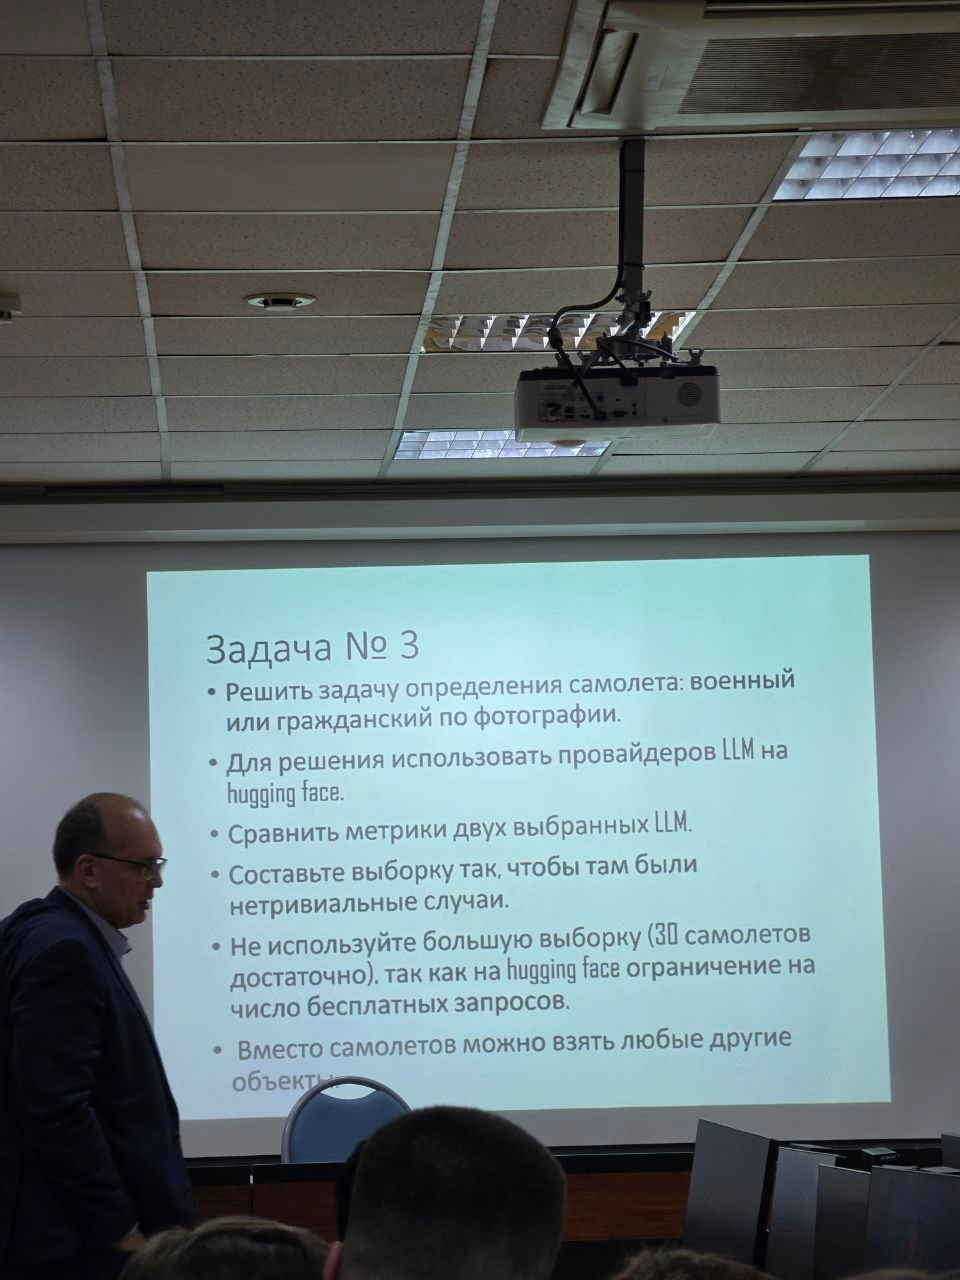

Задача № 3- Решить задачу определения самолета: военный или гражданский по фотографии.
- Для решения использовать провайдеров LLM на hugging face.
- Сравнить метрики двух выбранных LLM.
- Составьте выборку так, чтобы там были нетривиальные случаи.
- Не используйте большую выборку (30 самолетов достаточно), так как на hugging face ограничение на число бесплатных запросов.
- Вместо самолетов можно взять любые другие объекты.

Исследуется классификация назначения самолётов: 30 исходных изображений из проверочной части FGVC-Aircraft 2013b и 10 преобразованных копий, по 5 каждого класса. Сопоставляются Qwen2.5-VL-3B-Instruct (`qwen2.5vl:3b`) и Gemma 3 4B IT (`gemma3:4b`). Каждый полный запуск выполняет 80 новых запросов, не считая двух проверочных. Бинарные метки назначены по типу самолёта. Гражданская часть содержит пассажирские и региональные типы; преобразования проверяют устойчивость распознавания, но не расширяют набор типов самолётов.

Источник: FGVC-Aircraft <https://www.robots.ox.ac.uk/~vgg/data/fgvc-aircraft/>; Maji et al., *Fine-Grained Visual Classification of Aircraft* (2013). Исследование проводится локально; моделям передаются полные исходные JPEG и преобразованные PNG. Рабочий каталог ядра должен быть `practice_3`.

## Подготовка выборки

Манифест задаёт неизменный состав выборки. Если все выбранные JPEG уже доступны, проверяются состав, метки и SHA-256 файлов без обращения к сети и архиву. Это проверка локальной целостности, а не повторная сверка с исходными аннотациями. Если данных недостаточно, используется архив FGVC-Aircraft с официальной страницы; HTTPS проверяется по корневым сертификатам `certifi`. Допустимы две известные MD5: `d4acdd33327262359767eeaa97a4f732` ранее использованного архива и `32eca553f897e747706144f3bb444df0`, опубликованная Oxford. При работе с архивом дополнительно сверяются аннотации и SHA-256 снимков; существующие JPEG не перезаписываются.

In [1]:
from pathlib import Path
import csv, hashlib, tarfile, urllib.request, json, time, base64, os, ssl, shutil
import certifi
from collections import Counter
import requests
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance, ImageFilter
from IPython.display import display

ROOT = Path.cwd()
DATA = ROOT / 'data'
IMAGES = DATA / 'images'
DATA.mkdir(exist_ok=True)
IMAGES.mkdir(exist_ok=True)
ARCHIVE = DATA / 'fgvc-aircraft-2013b.tar.gz'
ARCHIVE_URL = 'https://www.robots.ox.ac.uk/~vgg/data/fgvc-aircraft/archives/fgvc-aircraft-2013b.tar.gz'
ARCHIVE_MD5 = 'd4acdd33327262359767eeaa97a4f732'
OXFORD_MD5 = '32eca553f897e747706144f3bb444df0'

# Локальные снимки проверяются по манифесту; архив требуется только для восстановления недостающих данных
def prepare_dataset():
    manifest_path = DATA / 'manifest.csv'
    sample = {'0704268': 'civilian', '1881962': 'civilian', '1818227': 'civilian', '1237861': 'civilian', '0127496': 'civilian', '1700645': 'civilian', '1396941': 'civilian', '0065291': 'civilian', '0422938': 'civilian', '1788036': 'civilian', '1601262': 'civilian', '1586117': 'civilian', '1647701': 'civilian', '1222169': 'civilian', '0066278': 'civilian', '1317747': 'military', '2186726': 'military', '1997801': 'military', '1375880': 'military', '1362024': 'military', '0747565': 'military', '0141433': 'military', '1120498': 'military', '1764706': 'military', '2118873': 'military', '1966899': 'military', '1898052': 'military', '1244763': 'military', '1570911': 'military', '2163696': 'military'}
    if manifest_path.exists():
        with manifest_path.open(encoding='utf-8') as handle:
            rows = list(csv.DictReader(handle))
        assert len(rows) == len(sample) and {row['image_id'] for row in rows} == set(sample), 'Нарушен состав выборки'
        complete = True
        for row in rows:
            assert row['label'] == sample[row['image_id']] and row['split'] == 'test', f"Некорректная метка или часть выборки: {row['image_id']}"
            assert row['source_md5'] in (ARCHIVE_MD5, OXFORD_MD5), 'Неизвестная контрольная сумма исходного архива'
            image_path = IMAGES / f"{row['image_id']}.jpg"
            if image_path.exists():
                assert hashlib.sha256(image_path.read_bytes()).hexdigest() == row['image_sha256'], f"Не совпадает SHA-256 снимка: {row['image_id']}"
            else:
                complete = False
        if complete:
            print(f'Проверены {len(rows)} локальных снимков; загрузка архива не требуется.')
            return rows
    if not ARCHIVE.exists():
        temporary = ARCHIVE.with_suffix('.download')
        try:
            context = ssl.create_default_context(cafile=certifi.where())
            with urllib.request.urlopen(ARCHIVE_URL, context=context, timeout=60) as response, temporary.open('wb') as handle:
                shutil.copyfileobj(response, handle, length=1024 * 1024)
            temporary.replace(ARCHIVE)
        finally:
            temporary.unlink(missing_ok=True)
    # Архив читается частями, чтобы не размещать несколько гигабайт в оперативной памяти
    checksum = hashlib.md5()
    with ARCHIVE.open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            checksum.update(chunk)
    digest = checksum.hexdigest()
    assert digest in (ARCHIVE_MD5, OXFORD_MD5), f'Не совпадает MD5 архива: {digest}'
    print(f'Архив проверен: MD5 {digest}')
    if not manifest_path.exists():
        with tarfile.open(ARCHIVE, 'r:gz') as source:
            members = {Path(member.name).name: member for member in source.getmembers() if member.isfile()}
            variants = source.extractfile(members['images_variant_test.txt']).read().decode().splitlines()
            boxes = source.extractfile(members['images_box.txt']).read().decode().splitlines()
            variants_by_id = {line.split(' ', 1)[0]: line.split(' ', 1)[1] for line in variants}
            boxes_by_id = {line.split()[0]: line.split()[1:] for line in boxes}
            rows = []
            for image_id, label in sample.items():
                box = list(map(int, boxes_by_id[image_id]))
                image_member = members[f'{image_id}.jpg']
                image_bytes = source.extractfile(image_member).read()
                rows.append({'image_id': image_id, 'variant': variants_by_id[image_id], 'split': 'test', 'label': label, 'selection_reason': 'Approved fixed sample', 'difficulty': 'not independently assessed', 'source': 'Oxford FGVC-Aircraft 2013b', 'source_md5': digest, 'image_sha256': hashlib.sha256(image_bytes).hexdigest(), 'bbox_xyxy': ','.join(map(str, box))})
        generated_manifest = DATA / 'manifest.csv.tmp'
        with generated_manifest.open('w', newline='', encoding='utf-8') as handle:
            writer = csv.DictWriter(handle, fieldnames=rows[0].keys())
            writer.writeheader()
            writer.writerows(rows)
        generated_manifest.replace(manifest_path)
    rows = list(csv.DictReader(manifest_path.open(encoding='utf-8')))
    assert len(rows) == 30 and {row['image_id'] for row in rows} == set(sample)
    assert Counter(row['label'] for row in rows) == {'civilian': 15, 'military': 15}
    with tarfile.open(ARCHIVE, 'r:gz') as archive:
        names = {Path(member.name).name: member for member in archive.getmembers() if member.isfile()}
        variants = {line.split(' ', 1)[0]: line.split(' ', 1)[1] for line in archive.extractfile(names['images_variant_test.txt']).read().decode().splitlines()}
        boxes = {line.split()[0]: ','.join(line.split()[1:]) for line in archive.extractfile(names['images_box.txt']).read().decode().splitlines()}
        for row in rows:
            assert row['label'] == sample[row['image_id']] and row['variant'] == variants[row['image_id']] and row['split'] == 'test'
            assert row['source_md5'] in (ARCHIVE_MD5, OXFORD_MD5) and row['bbox_xyxy'] == boxes[row['image_id']], f'Manifest does not match pinned archive annotations: {row["image_id"]}'
            image_path = IMAGES / f"{row['image_id']}.jpg"
            member = names.get(f"{row['image_id']}.jpg")
            if member is None:
                raise FileNotFoundError(f"Image not found in official archive: {row['image_id']}")
            original_bytes = archive.extractfile(member).read()
            assert hashlib.sha256(original_bytes).hexdigest() == row['image_sha256'], f"Manifest image hash differs from archive: {row['image_id']}"
            if not image_path.exists():
                image_path.write_bytes(original_bytes)
            actual = hashlib.sha256(image_path.read_bytes()).hexdigest()
            assert actual == row['image_sha256'], f"JPEG SHA-256 mismatch: {row['image_id']}"
    print(f'Validated {len(rows)} original test images; labels: {dict(Counter(row["label"] for row in rows))}')
    return rows

manifest = prepare_dataset()

Проверены 30 локальных снимков; загрузка архива не требуется.


Рамки FGVC применяются только к отображению. Оригинальный JPEG сверяется с хешем манифеста, но в HTTP-запрос отправляется подготовленная копия: длинная сторона ограничена 896 px, сжатие JPEG q85. Хеш отправленных байтов фиксируется в `prepared_sha256`, исходный файл не меняется

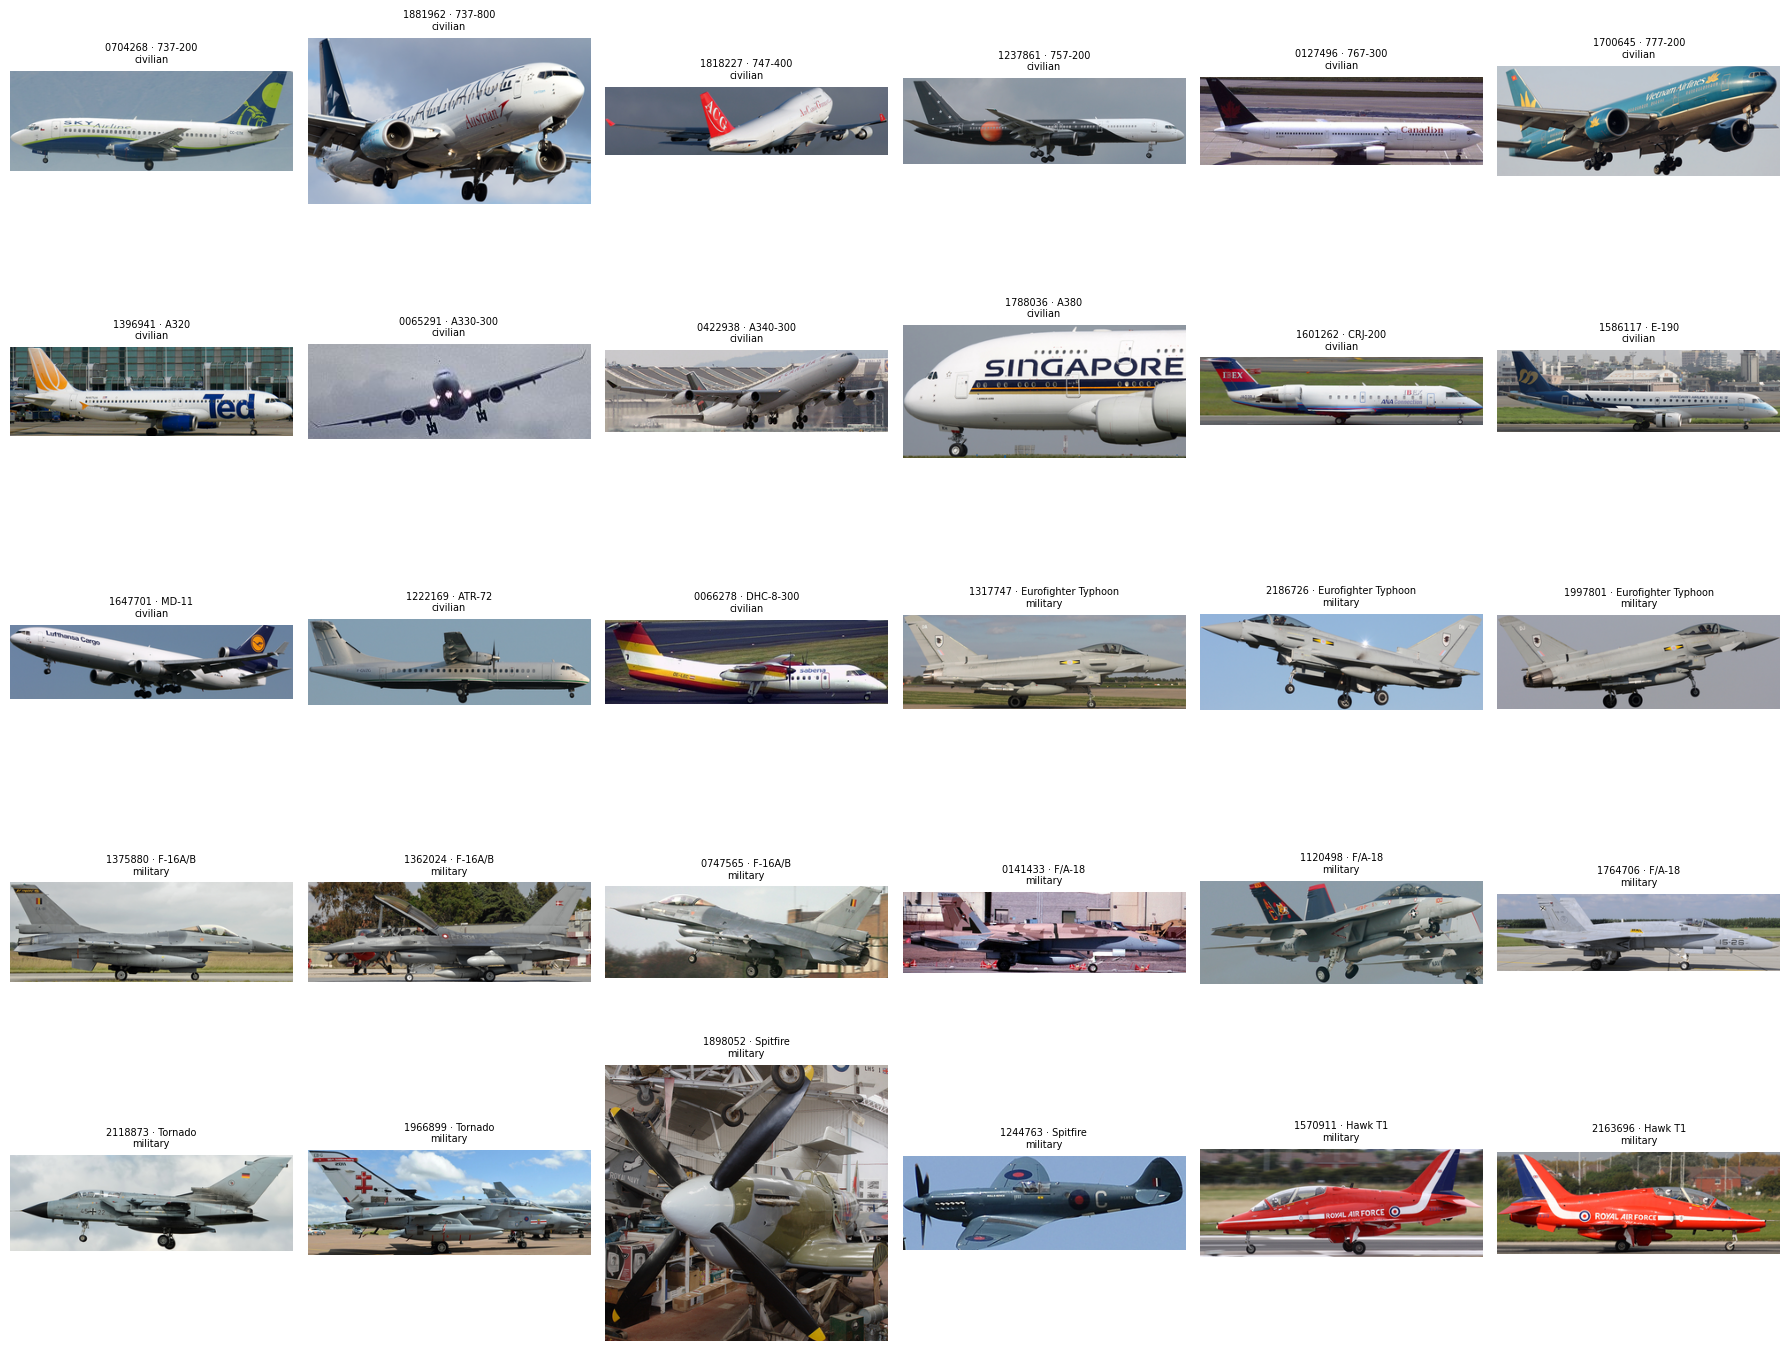

In [2]:
fig, axes = plt.subplots(5, 6, figsize=(18, 14))
try:
    for ax, row in zip(axes.flat, manifest):
        with Image.open(IMAGES / f"{row['image_id']}.jpg") as image:
            x0, y0, x1, y1 = map(int, row['bbox_xyxy'].split(','))
            thumbnail = image.crop((x0, y0, x1, y1))
            try:
                thumbnail.thumbnail((320, 320), Image.Resampling.LANCZOS)
                ax.imshow(thumbnail)
            finally:
                thumbnail.close()
        ax.set_title(f"{row['image_id']} · {row['variant']}\n{row['label']}", fontsize=7)
        ax.axis('off')
    plt.tight_layout()
    plt.show()
finally:
    plt.close(fig)


## Усложнение выборки

Заранее выбраны пять разных исходников каждого класса, без отбора по ответам моделей. Для обоих классов применяются одинаковые преобразования: яркость 20% исходной, поворот на 35°, гауссово размытие с радиусом 5 пикселей, уменьшение длинной стороны до 96 пикселей с восстановлением размера, затемнение до 25% вместе с поворотом на −30°. Поворот расширяет границы кадра и не обрезает самолёт.

Копии сохраняются отдельно в PNG без потерь; исходные JPEG не меняются. Параметры и контрольные суммы записываются в `data/manifest-extended.csv`. На обзорном листе показаны полные кадры, передаваемые моделям. Преобразованные изображения не являются независимыми наблюдениями; одного примера на класс недостаточно для вывода об отдельном виде искажения.

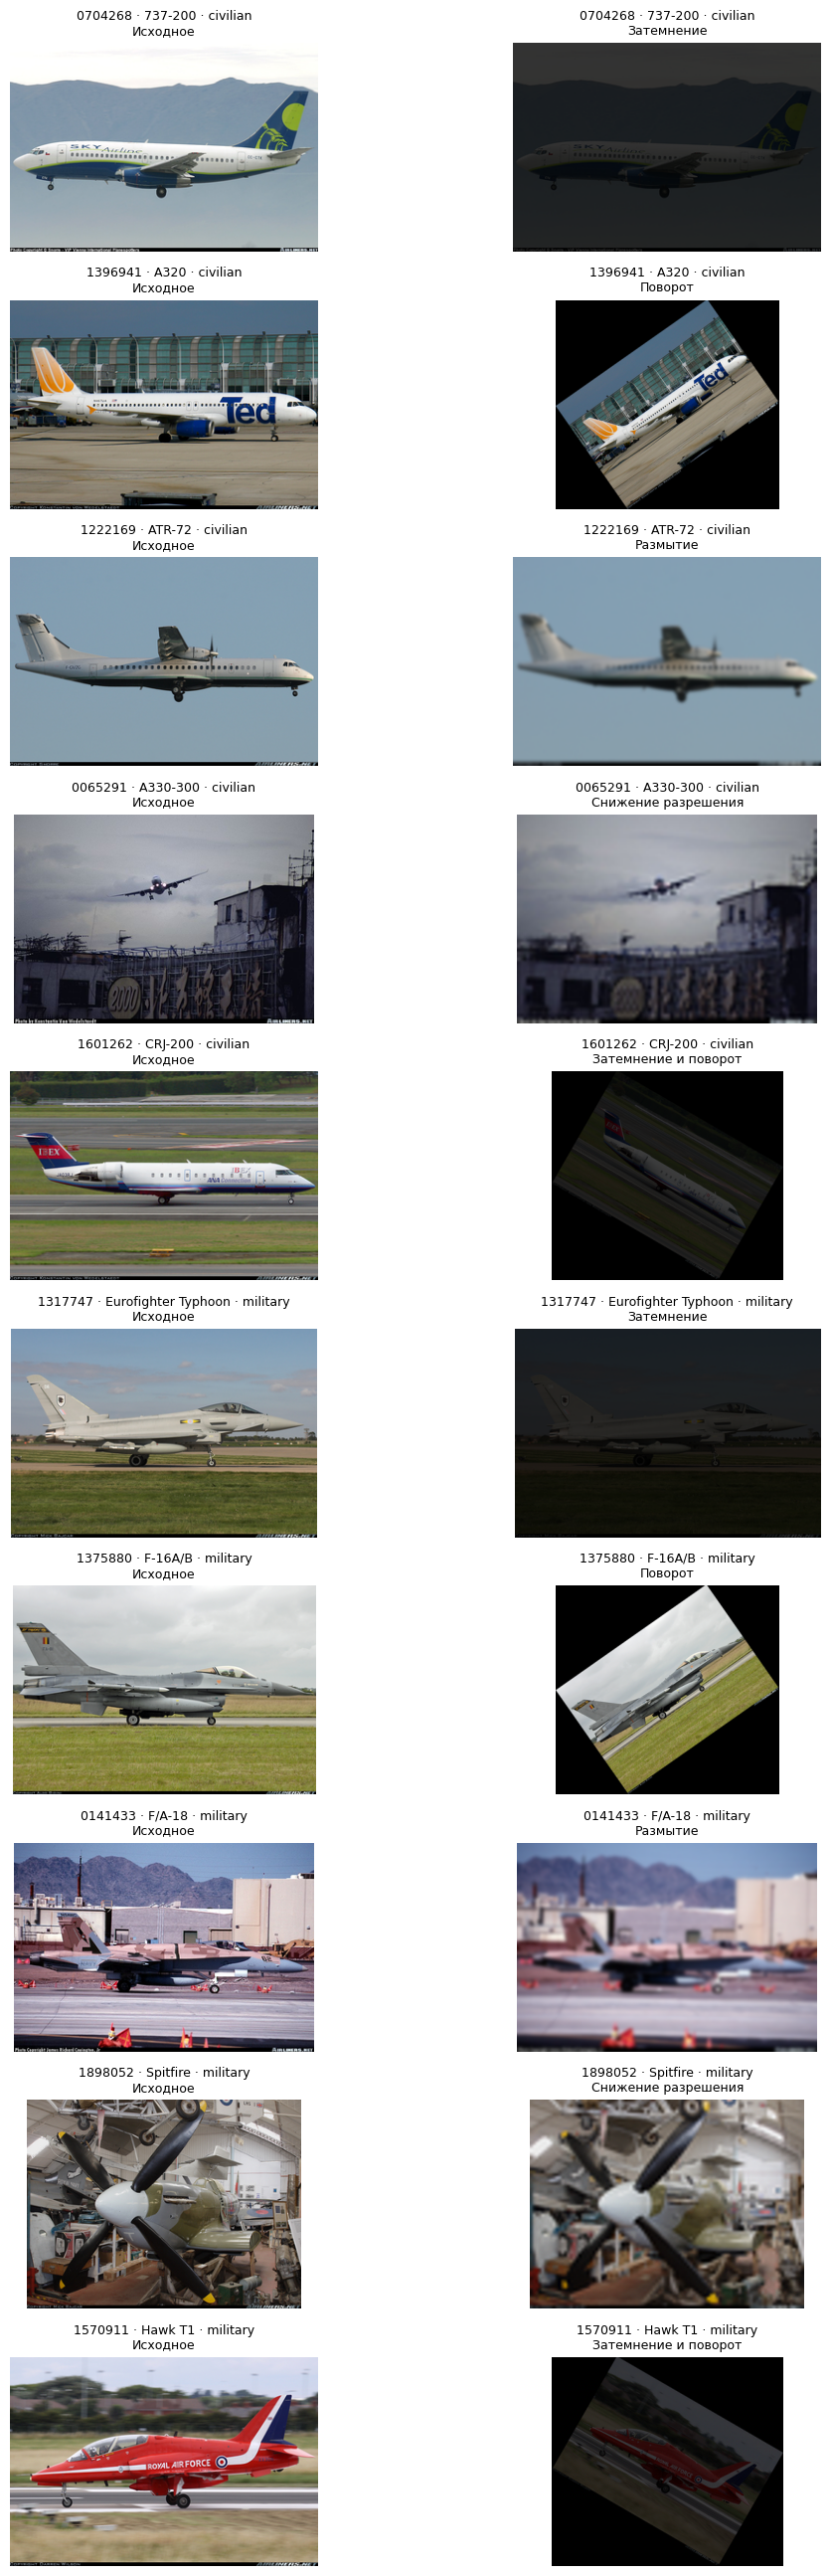

In [3]:
TRANSFORMS = ['Затемнение', 'Поворот', 'Размытие', 'Снижение разрешения', 'Затемнение и поворот']
TRANSFORM_PARAMETERS = ['яркость=0.20', 'угол=35°', 'радиус=5 пикселей', 'длинная сторона=96 пикселей', 'яркость=0.25; угол=-30°']
SELECTED = {'civilian': ['0704268', '1396941', '1222169', '0065291', '1601262'],
            'military': ['1317747', '1375880', '0141433', '1898052', '1570911']}

# Преобразования воспроизводимы; исходные файлы сохраняются, а копии получают собственные идентификаторы и контрольные суммы
def prepare_extended_dataset(originals):
    """Строит 40 записей из 30 исходников и закрывает все производные копии"""
    derived = DATA / 'transformed'
    derived.mkdir(exist_ok=True)
    samples = []
    for row in originals:
        path = IMAGES / f"{row['image_id']}.jpg"
        assert hashlib.sha256(path.read_bytes()).hexdigest() == row['image_sha256']
        samples.append({'image_id': row['image_id'], 'source_image_id': row['image_id'], 'variant': row['variant'], 'label': row['label'], 'condition': 'Исходное', 'parameters': '', 'image_path': str(path.relative_to(DATA)), 'image_sha256': row['image_sha256']})
    by_id = {row['image_id']: row for row in originals}
    for label, image_ids in SELECTED.items():
        for index, image_id in enumerate(image_ids):
            row = by_id[image_id]
            assert row['label'] == label
            with Image.open(IMAGES / f'{image_id}.jpg') as source_image:
                image = source_image.convert('RGB')
            try:
                if index == 0:
                    previous = image
                    image = None
                    try:
                        image = ImageEnhance.Brightness(previous).enhance(0.20)
                    finally:
                        previous.close()
                elif index == 1:
                    previous = image
                    image = None
                    try:
                        image = previous.rotate(35, resample=Image.Resampling.BICUBIC, expand=True)
                    finally:
                        previous.close()
                elif index == 2:
                    previous = image
                    image = None
                    try:
                        image = previous.filter(ImageFilter.GaussianBlur(radius=5))
                    finally:
                        previous.close()
                elif index == 3:
                    previous = image
                    image = None
                    try:
                        size = previous.size
                        previous.thumbnail((96, 96), Image.Resampling.LANCZOS)
                        image = previous.resize(size, Image.Resampling.BICUBIC)
                    finally:
                        previous.close()
                else:
                    previous = image
                    image = None
                    try:
                        image = ImageEnhance.Brightness(previous).enhance(0.25)
                    finally:
                        previous.close()
                    previous = image
                    image = None
                    try:
                        image = previous.rotate(-30, resample=Image.Resampling.BICUBIC, expand=True)
                    finally:
                        previous.close()
                sample_id = f'{image_id}_transformed_{index + 1}'
                path = derived / f'{sample_id}.png'
                image.save(path, format='PNG')
                samples.append({'image_id': sample_id, 'source_image_id': image_id, 'variant': row['variant'], 'label': label, 'condition': TRANSFORMS[index], 'parameters': TRANSFORM_PARAMETERS[index], 'image_path': str(path.relative_to(DATA)), 'image_sha256': hashlib.sha256(path.read_bytes()).hexdigest()})
            finally:
                if image is not None:
                    image.close()
    assert len(samples) == 40 and len({row['image_id'] for row in samples}) == len(samples)
    assert Counter(row['label'] for row in samples) == {'civilian': 20, 'military': 20}
    with (DATA / 'manifest-extended.csv').open('w', newline='', encoding='utf-8') as handle:
        writer = csv.DictWriter(handle, fieldnames=samples[0].keys())
        writer.writeheader()
        writer.writerows(samples)
    return samples

samples = prepare_extended_dataset(manifest)
transformed = [row for row in samples if row['condition'] != 'Исходное']
fig, axes = plt.subplots(len(transformed), 2, figsize=(12, 26))
try:
    # В каждой строке показана пара полных кадров, а не обрезка по ограничивающей рамке
    for axes_pair, row in zip(axes, transformed):
        paths = [IMAGES / f"{row['source_image_id']}.jpg", DATA / row['image_path']]
        for ax, path, title in zip(axes_pair, paths, ['Исходное', row['condition']]):
            with Image.open(path) as image:
                thumbnail = image.copy()
                try:
                    thumbnail.thumbnail((320, 320), Image.Resampling.LANCZOS)
                    ax.imshow(thumbnail)
                finally:
                    thumbnail.close()
            ax.set_title(f"{row['source_image_id']} · {row['variant']} · {row['label']}\n{title}", fontsize=9)
            ax.axis('off')
    plt.tight_layout()
    plt.show()
finally:
    plt.close(fig)


## Подготовка локальной среды моделей

Отдельный bootstrap использует только именованные ресурсы практикума. Проверка GPU показывает доступную память до загрузки; процессы вне контейнеров не завершаются автоматически.


In [4]:
from ollama_runtime import bootstrap
import subprocess
bootstrap()
# Диагностика GPU выполняется внутри Ollama-контейнера: у bootstrap-образа нет nvidia-smi
gpu = subprocess.run(["docker", "exec", "practice3-ollama", "nvidia-smi", "--query-gpu=name,memory.total,memory.used", "--format=csv,noheader"], capture_output=True, text=True)
if gpu.returncode:
    raise RuntimeError("GPU diagnostics unavailable; verify NVIDIA Container Toolkit and GPU access in the Ollama container")
print("GPU status:", gpu.stdout.strip())

GPU status: NVIDIA GeForce RTX 4060 Laptop GPU, 8188 MiB, 0 MiB


In [5]:
OLLAMA_URL = 'http://practice3-ollama:11434'
MODELS = ('qwen2.5vl:3b', 'gemma3:4b')
PROMPT = 'Определите основное назначение самолёта. Верните JSON-объект строго вида {"label": "civilian"} или {"label": "military"}.'
OPTIONS = {'temperature': 0, 'num_ctx': 4096, 'num_predict': 32}
REQUEST_TIMEOUT = 600
API_MAX_SIDE = 896
JPEG_QUALITY = 85
from io import BytesIO

def parse_label(raw):
    """Извлекает одну допустимую метку из строгого ответа модели"""
    try:
        value = json.loads(raw)
    except (json.JSONDecodeError, TypeError):
        value = None
    if isinstance(value, dict) and value.get('label') in ('civilian', 'military'):
        return value['label']
    return raw.strip() if isinstance(raw, str) and raw.strip() in ('civilian', 'military') else ''

def call_model(model, payload):
    """Отправляет подготовленный JPEG и возвращает ответ, длительность и ошибку"""
    body = {'model': model, 'messages': [{'role': 'user', 'content': PROMPT, 'images': [base64.b64encode(payload).decode('ascii')]}], 'stream': False, 'format': 'json', 'options': OPTIONS}
    started = time.perf_counter()
    try:
        response = requests.post(f'{OLLAMA_URL}/api/chat', json=body, timeout=REQUEST_TIMEOUT)
        response.raise_for_status()
        try:
            answer = response.json()
            # Корректный синтаксис JSON не гарантирует наличия текстового ответа модели
            if not isinstance(answer, dict) or not isinstance(answer.get('message'), dict) or not isinstance(answer['message'].get('content'), str):
                return {}, time.perf_counter() - started, 'Malformed response structure from server'
            duration = answer.get('total_duration')
            if duration is not None and (not isinstance(duration, (int, float)) or isinstance(duration, bool) or duration < 0):
                return {}, time.perf_counter() - started, 'Malformed total_duration in server response'
            return answer, time.perf_counter() - started, ''
        except (requests.exceptions.JSONDecodeError, ValueError) as exc:
            return {}, time.perf_counter() - started, f'Malformed JSON: {exc}'
    except requests.RequestException as exc:
        return {}, time.perf_counter() - started, f'{type(exc).__name__}: {exc}'

# Уменьшенный payload сокращает длину контекста vision-энкодера и пиковое потребление VRAM
def prepare_payload(image_bytes):
    """Сжимает только отправляемую копию изображения и закрывает временные ресурсы"""
    with BytesIO(image_bytes) as source_buffer:
        with Image.open(source_buffer) as image:
            image.load()
            if max(image.size) <= API_MAX_SIDE:
                return image_bytes
            converted = image.convert('RGB')
            try:
                converted.thumbnail((API_MAX_SIDE, API_MAX_SIDE), Image.Resampling.LANCZOS)
                with BytesIO() as output:
                    converted.save(output, format='JPEG', quality=JPEG_QUALITY)
                    return output.getvalue()
            finally:
                converted.close()

version_response = requests.get(f'{OLLAMA_URL}/api/version', timeout=30)
version_response.raise_for_status()
ollama_version = version_response.json()['version']
print(f'Ollama version: {ollama_version}')
# Теги загружаются перед опытом, а их digest связывает ответы с конкретными версиями моделей
tags_response = requests.get(f'{OLLAMA_URL}/api/tags', timeout=30)
tags_response.raise_for_status()
tag_rows = {item['name']: item for item in tags_response.json().get('models', [])}
for model in MODELS:
    if model not in tag_rows:
        pull_response = requests.post(f'{OLLAMA_URL}/api/pull', json={'name': model, 'stream': False}, timeout=1800)
        pull_response.raise_for_status()
        tags_response = requests.get(f'{OLLAMA_URL}/api/tags', timeout=30)
        tags_response.raise_for_status()
        tag_rows = {item['name']: item for item in tags_response.json().get('models', [])}
digests = {model: tag_rows[model]['digest'] for model in MODELS if model in tag_rows}
assert len(digests) == 2, f'Model tags missing after pull: {set(MODELS) - set(digests)}'
def unload_and_wait(model=None):
    """Выгружает указанную или текущую модель и ограниченно ждёт освобождения VRAM"""
    model = model or current_model
    if not model:
        return
    requests.post(f'{OLLAMA_URL}/api/chat', json={'model': model, 'keep_alive': 0}, timeout=60).raise_for_status()
    deadline = time.monotonic() + 120
    while time.monotonic() < deadline:
        state = requests.get(f'{OLLAMA_URL}/api/ps', timeout=10)
        state.raise_for_status()
        if not state.json().get('models'):
            return
        time.sleep(2)
    raise RuntimeError('Previous model did not unload before timeout; check Ollama logs and GPU memory')

pilot_bytes = (IMAGES / f"{manifest[0]['image_id']}.jpg").read_bytes()
assert hashlib.sha256(pilot_bytes).hexdigest() == manifest[0]['image_sha256']
pilot_payload = prepare_payload(pilot_bytes)
current_model = None
try:
    for model in MODELS:
        if current_model:
            unload_and_wait()
        current_model = model
        pilot, _, error = call_model(model, pilot_payload)
        raw = pilot.get('message', {}).get('content', '')
        assert not error and parse_label(raw), f'Invalid pilot response from {model}: {error or raw}'
    print('Visual pilot passed for both models.')
finally:
    try:
        unload_and_wait()
    finally:
        current_model = None


Ollama version: 0.30.7


Visual pilot passed for both models.


## Полный сбор ответов

Для каждой из 40 выборок выполняется отдельный новый запрос каждой модели: всего 80 запросов. Все строки, включая ошибки и некорректные ответы, остаются в текущем эксперименте и учитываются при расчёте показателей. Результаты расширенной выборки записываются в `data/results-extended.csv` только после полной проверки состава; каждый ответ сразу сохраняется в `data/results-extended-partial.csv`, поэтому прогресс переживает прерывание сбора. Ошибки 500 и таймауты допускают не более одного повтора с паузой 120 с (всего не более двух попыток), после чего сбор останавливается и сохранённый частичный CSV не считается полным отчётом. Сбор идёт пачками по два запроса с паузой 90 с, чтобы снизить непрерывную нагрузку на видеодрайвер WSL. Время сравнивается только внутри нового запуска, без смешивания с прежними измерениями

In [6]:
fields = ['model', 'model_digest', 'ollama_version', 'image_id', 'source_image_id', 'condition', 'parameters', 'variant', 'ground_truth', 'status', 'predicted_label', 'raw_response', 'error', 'wall_seconds', 'server_seconds', 'prepared_sha256']
records = []
partial_results = DATA / 'results-extended-partial.csv'
def save_partial():
    """Атомарно сохраняет наблюдаемый прогресс, не трогая успешный отчёт"""
    temporary = partial_results.with_suffix('.csv.tmp')
    with temporary.open('w', newline='', encoding='utf-8') as handle:
        writer = csv.DictWriter(handle, fieldnames=fields)
        writer.writeheader()
        writer.writerows(records)
    temporary.replace(partial_results)
BATCH_SIZE = 2
BATCH_PAUSE_SECONDS = 90
TRANSIENT_RETRIES = 1
TRANSIENT_COOLDOWN_SECONDS = 120

# Повтор оправдан только для ошибок перегрузки: HTTP 500, сетевые таймауты и разрыв соединения
def is_transient(error):
    """Определяет ошибки, допускающие ограниченное число повторных попыток"""
    connection = 'Timeout' in error or 'timed out' in error or 'ConnectionError' in error
    server_error = 'HTTPError' in error and ' 500 ' in error
    return connection or server_error

pairs = [(model, row) for model in MODELS for row in samples]
total_batches = (len(pairs) + BATCH_SIZE - 1) // BATCH_SIZE
try:
    for batch_start in range(0, len(pairs), BATCH_SIZE):
        batch_index = batch_start // BATCH_SIZE + 1
        if batch_index > 1:
            time.sleep(BATCH_PAUSE_SECONDS)
        print(f'Batch {batch_index}/{total_batches}: requests {batch_start + 1}-{min(batch_start + BATCH_SIZE, len(pairs))}')
        for model, row in pairs[batch_start:batch_start + BATCH_SIZE]:
            if current_model != model:
                unload_and_wait()
                current_model = model
            image_bytes = (DATA / row['image_path']).read_bytes()
            image_hash = hashlib.sha256(image_bytes).hexdigest()
            assert image_hash == row['image_sha256'], f"Изображение изменилось во время опыта: {row['image_id']}"
            # prepared_sha256 описывает именно отправленные байты, а не исходный файл
            payload = prepare_payload(image_bytes)
            prepared_hash = hashlib.sha256(payload).hexdigest()
            attempts = 0
            while True:
                answer, elapsed, error = call_model(model, payload)
                attempts += 1
                if not is_transient(error) or attempts > TRANSIENT_RETRIES:
                    break
                # Пауза после неудачи даёт драйверу и Ollama время освободить память
                print(f'Transient failure on attempt {attempts}/{TRANSIENT_RETRIES + 1}; retrying after {TRANSIENT_COOLDOWN_SECONDS}s: {error}')
                time.sleep(TRANSIENT_COOLDOWN_SECONDS)
            raw = answer.get('message', {}).get('content', '')
            predicted = parse_label(raw) if not error else ''
            # Успех требует валидной метки; таймаут, прочая ошибка и пустой разбор различаются по статусу
            status = 'timeout' if 'Timeout' in error else ('error' if error else ('ok' if predicted else 'invalid'))
            server_ns = answer.get('total_duration')
            records.append({'model': model, 'model_digest': digests[model], 'ollama_version': ollama_version, 'image_id': row['image_id'], 'source_image_id': row['source_image_id'], 'condition': row['condition'], 'parameters': row['parameters'], 'variant': row['variant'], 'ground_truth': row['label'], 'status': status, 'predicted_label': predicted, 'raw_response': raw, 'error': error, 'wall_seconds': elapsed, 'server_seconds': server_ns / 1e9 if server_ns is not None else '', 'prepared_sha256': prepared_hash})
            save_partial()
            print(f"{model} {row['image_id']}: {status}, {elapsed:.2f}s")
            if status in ('timeout', 'error'):
                # Повторы исчерпаны: сбор честно останавливается, частичный CSV сохранён и не выдаётся за полный отчёт
                raise RuntimeError(f'Collection stopped after repeated transient failures for {model} {row["image_id"]}: {error}. Partial progress: {partial_results}')

    expected = {(model, row['image_id']) for model in MODELS for row in samples}
    actual = {(record['model'], record['image_id']) for record in records}
    # Полнота означает наличие ответа или диагностики для каждой пары; некорректный ответ не прерывает расчёт показателей
    if len(records) != len(expected) or actual != expected:
        raise RuntimeError(f'Нарушена полнота сбора: {len(records)}/{len(expected)} записей. Промежуточные результаты: {partial_results}')
    # Сначала записывается временный файл; заменяется только готовый полный результат
    temporary_results = DATA / 'results-extended.csv.tmp'
    with temporary_results.open('w', newline='', encoding='utf-8') as handle:
        writer = csv.DictWriter(handle, fieldnames=fields)
        writer.writeheader()
        writer.writerows(records)
    temporary_results.replace(DATA / 'results-extended.csv')
    partial_results.unlink(missing_ok=True)
    df = pd.DataFrame(records)
    print(f'Completed fresh collection: {len(df)} records; {df["status"].value_counts().to_dict()}')
finally:
    try:
        unload_and_wait()
    finally:
        current_model = None


Batch 1/40: requests 1-2


qwen2.5vl:3b 0704268: ok, 92.73s


qwen2.5vl:3b 1881962: ok, 71.98s


Batch 2/40: requests 3-4


qwen2.5vl:3b 1818227: ok, 85.60s


...

gemma3:4b 0141433_transformed_3: ok, 46.11s


Batch 40/40: requests 79-80


gemma3:4b 1898052_transformed_4: ok, 46.75s


gemma3:4b 1570911_transformed_5: ok, 45.71s


Completed fresh collection: 80 records; {'ok': 80}


## Метрики, матрицы ошибок и задержки

Показатели рассчитываются из массива текущего запуска. Ошибочные и некорректные ответы остаются в знаменателе доли правильных ответов и отображаются отдельным столбцом матрицы. Общая сводка описывает все 40 снимков, а ниже отдельно сопоставляются 10 пар. Времена сравниваются с ориентиром 120 секунд без предположения о гарантированном соблюдении порога.

,model,accuracy,invalid_or_timeout,within_120s,requests,median_wall_s,max_wall_s,civilian_precision,civilian_recall,civilian_f1,military_precision,military_recall,military_f1
0,qwen2.5vl:3b,0.975,0,40,40,77.323929,101.543653,1.0,0.95,0.974359,0.952381,1.0,0.975610
1,gemma3:4b,0.925,0,40,40,47.130959,94.465419,1.0,0.85,0.918919,0.869565,1.0,0.930233


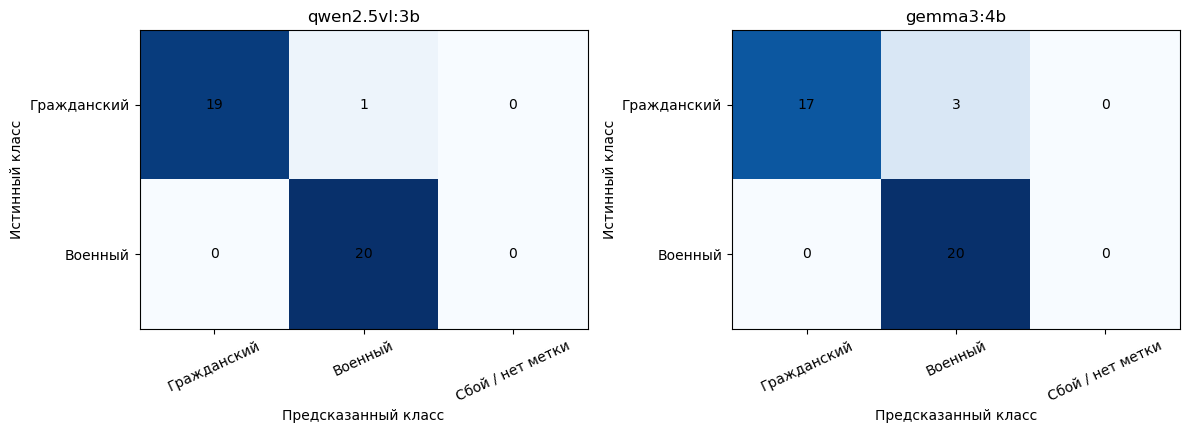

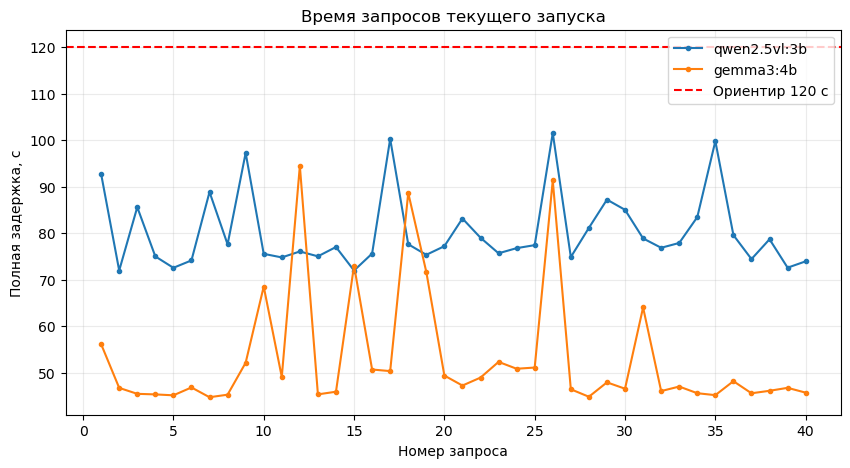

qwen2.5vl:3b: доля правильных ответов 97.5%; в пределах 120 с 40/40; медиана 77.32 с; максимум 101.54 с; сбоев или некорректных ответов 0
gemma3:4b: доля правильных ответов 92.5%; в пределах 120 с 40/40; медиана 47.13 с; максимум 94.47 с; сбоев или некорректных ответов 0
Итог текущего сбора: все 80 запросов завершились корректными ответами.


In [7]:
from sklearn.metrics import precision_recall_fscore_support
labels = ['civilian', 'military']
summaries = []
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
try:
    for index, model in enumerate(MODELS):
        group = df[df['model'] == model]
        truth = group['ground_truth'].tolist()
        # Ошибки и таймауты не исключаются из accuracy и попадают в отдельный столбец матрицы
        predictions = [value if status == 'ok' and value in labels else 'invalid/timeout' for value, status in zip(group['predicted_label'], group['status'])]
        safe_predictions = [value if value in labels else '__invalid__' for value in predictions]
        precision, recall, f1, _ = precision_recall_fscore_support(truth, safe_predictions, labels=labels, zero_division=0)
        wall = group['wall_seconds'].astype(float)
        summaries.append({'model': model, 'accuracy': sum(a == b for a, b in zip(truth, safe_predictions)) / len(truth), 'invalid_or_timeout': predictions.count('invalid/timeout'), 'within_120s': int((wall <= 120).sum()), 'requests': len(group), 'median_wall_s': wall.median(), 'max_wall_s': wall.max(), 'civilian_precision': precision[0], 'civilian_recall': recall[0], 'civilian_f1': f1[0], 'military_precision': precision[1], 'military_recall': recall[1], 'military_f1': f1[1]})
        matrix = [[sum(t == target and pred == column for t, pred in zip(truth, predictions)) for column in labels + ['invalid/timeout']] for target in labels]
        # Общая цветовая шкала позволяет сопоставлять частоты ошибок двух моделей
        axes[index].imshow(matrix, cmap='Blues', vmin=0, vmax=max(Counter(row['label'] for row in samples).values()))
        axes[index].set(xticks=range(3), yticks=range(2), xticklabels=['Гражданский', 'Военный', 'Сбой / нет метки'], yticklabels=['Гражданский', 'Военный'], xlabel='Предсказанный класс', ylabel='Истинный класс', title=model)
        for (i, j), value in __import__('numpy').ndenumerate(matrix):
            axes[index].text(j, i, str(value), ha='center', va='center')
        axes[index].tick_params(axis='x', labelrotation=25)
    summary = pd.DataFrame(summaries)
    display(summary)
    plt.tight_layout()
    plt.show()
finally:
    plt.close(fig)
fig, ax = plt.subplots(figsize=(10, 5))
try:
    for model in MODELS:
        group = df[df['model'] == model]
        ax.plot(range(1, len(group) + 1), group['wall_seconds'], marker='.', label=model)
    ax.axhline(120, color='red', linestyle='--', label='Ориентир 120 с')
    ax.set(xlabel='Номер запроса', ylabel='Полная задержка, с', title='Время запросов текущего запуска')
    ax.legend()
    ax.grid(alpha=.25)
    plt.show()
finally:
    plt.close(fig)
for row in summaries:
    print(f"{row['model']}: доля правильных ответов {row['accuracy']:.1%}; в пределах 120 с {row['within_120s']}/{row['requests']}; медиана {row['median_wall_s']:.2f} с; максимум {row['max_wall_s']:.2f} с; сбоев или некорректных ответов {row['invalid_or_timeout']}")
if df['status'].eq('ok').all():
    print(f'Итог текущего сбора: все {len(df)} запросов завершились корректными ответами.')
else:
    failed_pairs = df.loc[df['status'] != 'ok', ['model', 'image_id', 'status']]
    print(f'Итог текущего сбора: успешно {int(df["status"].eq("ok").sum())}/{len(df)}; неуспешные пары: {failed_pairs.to_dict("records")}')


## Устойчивость к искажениям

Сравниваются только 10 выбранных исходных снимков и их 10 преобразованных копий. Для каждой модели таблица показывает изменение правильности ответа в каждой паре, а диаграмма — долю правильных ответов до и после преобразования. Сбои считаются неправильными ответами. Снижение доли правильных ответов выражается в процентных пунктах.

Диаграмма распределения времени использует те же пары: центральная линия — медиана, границы прямоугольника — первый и третий квартили, усы — крайние значения в пределах полутора межквартильных размахов; отдельные точки обозначают выбросы. Измеряется полное время запроса, включая неуспешные попытки.

,Модель,Исходный снимок,Преобразование,Верно до,Верно после
0,qwen2.5vl:3b,0704268,Затемнение,True,True
1,qwen2.5vl:3b,1396941,Поворот,True,True
2,qwen2.5vl:3b,1222169,Размытие,True,True
3,qwen2.5vl:3b,0065291,Снижение разрешения,True,False
4,qwen2.5vl:3b,1601262,Затемнение и поворот,True,True
5,qwen2.5vl:3b,1317747,Затемнение,True,True
6,qwen2.5vl:3b,1375880,Поворот,True,True
7,qwen2.5vl:3b,0141433,Размытие,True,True
8,qwen2.5vl:3b,1898052,Снижение разрешения,True,True
9,qwen2.5vl:3b,1570911,Затемнение и поворот,True,True


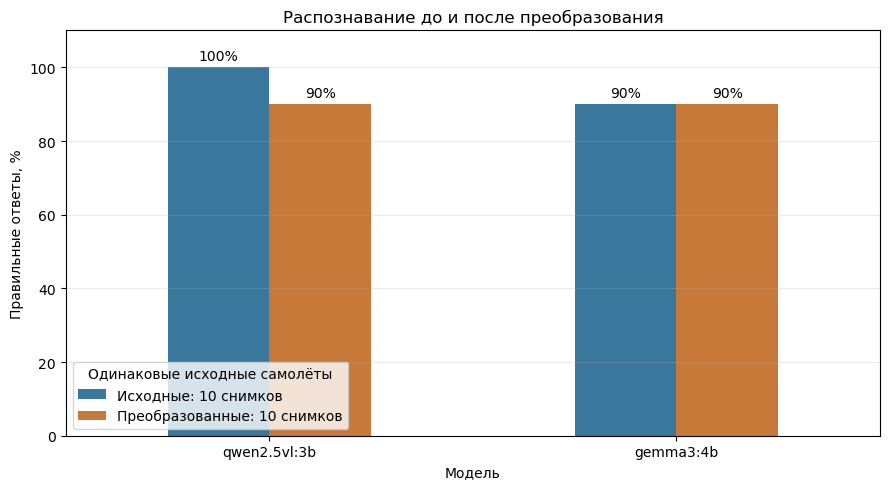

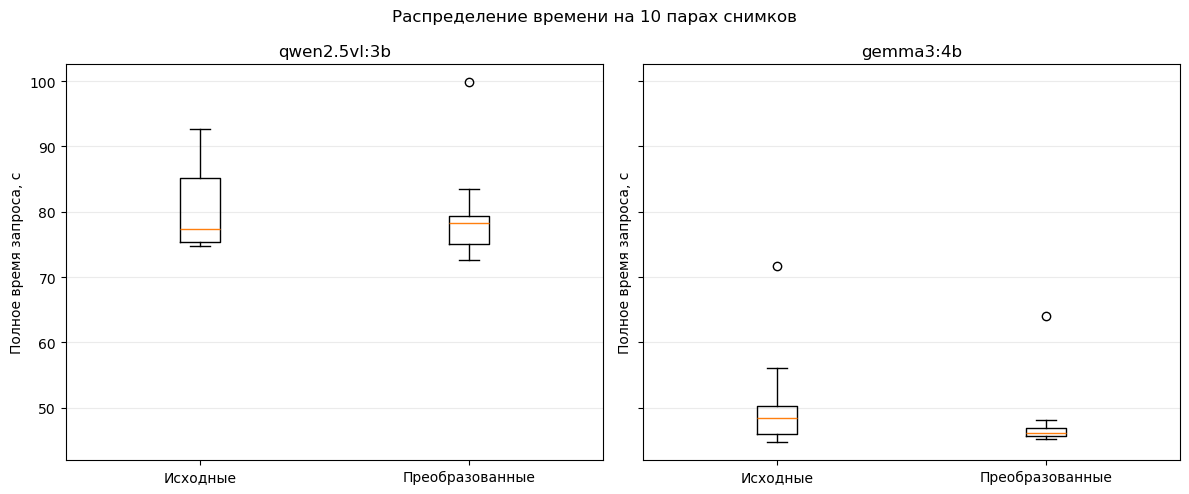

qwen2.5vl:3b: верно до 100%, после 90%; снижение 10 п.п.; переходов из правильного ответа в ошибку 1, обратных переходов 0.
gemma3:4b: верно до 90%, после 90%; снижение 0 п.п.; переходов из правильного ответа в ошибку 1, обратных переходов 1.


In [8]:
evaluated = df.assign(correct=df['status'].eq('ok') & df['predicted_label'].eq(df['ground_truth']))
original = evaluated[evaluated['condition'].eq('Исходное')]
changed = evaluated[~evaluated['condition'].eq('Исходное')]
# Соединение по модели и исходному снимку исключает сравнение разных составов выборки
pairs = changed.merge(original[['model', 'image_id', 'correct', 'wall_seconds']], left_on=['model', 'source_image_id'], right_on=['model', 'image_id'], suffixes=('_changed', '_original'), validate='one_to_one')
assert len(pairs) == len(changed) == len(MODELS) * len(transformed)
paired_quality = pairs.groupby('model', sort=False)[['correct_original', 'correct_changed']].mean().reindex(MODELS)
pair_table = pairs[['model', 'source_image_id', 'condition', 'correct_original', 'correct_changed']].rename(columns={'model': 'Модель', 'source_image_id': 'Исходный снимок', 'condition': 'Преобразование', 'correct_original': 'Верно до', 'correct_changed': 'Верно после'})
display(pair_table)
fig, ax = plt.subplots(figsize=(9, 5))
try:
    (paired_quality * 100).rename(columns={'correct_original': 'Исходные: 10 снимков', 'correct_changed': 'Преобразованные: 10 снимков'}).plot.bar(ax=ax, rot=0, color=['#39779c', '#c7793a'])
    ax.set(xlabel='Модель', ylabel='Правильные ответы, %', ylim=(0, 110), title='Распознавание до и после преобразования')
    for container in ax.containers:
        ax.bar_label(container, fmt='%.0f%%', padding=3)
    ax.grid(axis='y', alpha=.25)
    ax.legend(title='Одинаковые исходные самолёты')
    plt.tight_layout()
    plt.show()
finally:
    plt.close(fig)

fig, axes = plt.subplots(1, len(MODELS), figsize=(12, 5), sharey=True)
try:
    for ax, model in zip(axes, MODELS):
        group = pairs[pairs['model'].eq(model)]
        ax.boxplot([group['wall_seconds_original'].astype(float), group['wall_seconds_changed'].astype(float)])
        ax.set(xticks=[1, 2], xticklabels=['Исходные', 'Преобразованные'], title=model, ylabel='Полное время запроса, с')
        ax.grid(axis='y', alpha=.25)
    fig.suptitle('Распределение времени на 10 парах снимков')
    plt.tight_layout()
    plt.show()
finally:
    plt.close(fig)

# Численные выводы формируются из текущего опыта, а не из сохранённых результатов предыдущего запуска
for model, quality in paired_quality.iterrows():
    group = pairs[pairs['model'].eq(model)]
    degraded = int((group['correct_original'] & ~group['correct_changed']).sum())
    improved = int((~group['correct_original'] & group['correct_changed']).sum())
    drop = 100 * (quality['correct_original'] - quality['correct_changed'])
    print(f"{model}: верно до {quality['correct_original']:.0%}, после {quality['correct_changed']:.0%}; снижение {drop:.0f} п.п.; переходов из правильного ответа в ошибку {degraded}, обратных переходов {improved}.")


# Вывод
В текущем опыте обе модели отвечали корректно во всех 80 запросах, но правильно определили класс не всегда: Qwen2.5-VL-3B — 39 из 40 снимков (97,5%), Gemma 3 4B — 37 из 40 (92,5%). Все запросы уложились в ориентир 120 секунд; медианное время Gemma (47,13 с) заметно меньше, чем у Qwen (77,32 с). По качеству на этой выборке впереди Qwen, по скорости — Gemma

Сводка и парное сравнение выше построены на измерениях этого запуска, а результаты исходного опыта на 30 фотографиях сохранены в `data/results.csv` как отдельная оценка

Усложнённая выборка проверяет устойчивость к ухудшению освещения, изменению ориентации и потере пространственных деталей. 